<a href="https://colab.research.google.com/github/aong2hehms/DL_Session7/blob/main/Tugas_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tahap 1

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [3]:
#Menentukan device gpu
device = torch.device("cuda" if torch.cuda.is_available()else "cpu")
print("Device: ",device)

Device:  cpu


In [4]:
#Load data
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform = transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root = './data',
    train = False,
    download = True,
    transform = transform
)
train_Loader = DataLoader(
    train_dataset,
    batch_size = 64,
    shuffle = True

)

test_loader = DataLoader(
    test_dataset,
    batch_size = 64,
    shuffle= False
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]


In [13]:
#membuat arsitektur MLPClassifier
class MLPClassifier(nn.Module):
    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), 784)

        x = self.relu(self.fc1(x))
        z = self.relu(self.fc2(x))

        x = self.fc3(z)

        return x, z

In [14]:
#inisialisasi model
model = MLPClassifier().to(device)
criterion =  nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)

In [ ]:
# Training model
epochs =30

for epochs in range(epochs):
  model.train()

  total_loss=0

  for images,labels in train_Loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    outputs, z = model(images)

    loss = criterion (outputs,labels)
    loss.backward()

    optimizer.step()
    total_loss += loss.item()

    print(
        f"epoch [{epochs+1}/{epochs}],"
        f'loss: {total_loss/len(train_Loader):.4f}'
    )

Streaming output truncated to the last 5000 lines.
epoch [25/24],loss: 0.0264
epoch [25/24],loss: 0.0266
epoch [25/24],loss: 0.0267
epoch [25/24],loss: 0.0269
epoch [25/24],loss: 0.0270
epoch [25/24],loss: 0.0271
epoch [25/24],loss: 0.0272
epoch [25/24],loss: 0.0273
epoch [25/24],loss: 0.0275
epoch [25/24],loss: 0.0276
epoch [25/24],loss: 0.0276
epoch [25/24],loss: 0.0280
epoch [25/24],loss: 0.0281
epoch [25/24],loss: 0.0282
epoch [25/24],loss: 0.0283
epoch [25/24],loss: 0.0284
epoch [25/24],loss: 0.0285
epoch [25/24],loss: 0.0286
epoch [25/24],loss: 0.0288
epoch [25/24],loss: 0.0289
epoch [25/24],loss: 0.0291
epoch [25/24],loss: 0.0293
epoch [25/24],loss: 0.0295
epoch [25/24],loss: 0.0297
epoch [25/24],loss: 0.0298
epoch [25/24],loss: 0.0300
epoch [25/24],loss: 0.0301
epoch [25/24],loss: 0.0302
epoch [25/24],loss: 0.0303
epoch [25/24],loss: 0.0303
epoch [25/24],loss: 0.0305
epoch [25/24],loss: 0.0307
epoch [25/24],loss: 0.0307
epoch [25/24],loss: 0.0308
epoch [25/24],loss: 0.0309
epoc

In [64]:
#Evaluasi
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs, z = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 88.85%


In [65]:
#simpan bobot matrix
W1 = model.fc1.weight.data.cpu().clone()
W2 = model.fc2.weight.data.cpu().clone()
W3 = model.fc3.weight.data.cpu().clone()

torch.save({
    "W1": W1,
    "W2": W2,
    "W3": W3
}, "mlp_weights.pth")

#Tahap 2

In [74]:
#One hot factor class
import torch.nn.functional as F

target_class = 1

y = F.one_hot(
    torch.tensor(target_class),
    num_classes=10
).float()

print(y)

tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])


In [75]:
with torch.no_grad():
  z_hat = F.relu(W3.T @y)
  h1_hat = F.relu(W2.T @z_hat)
  x_hat = torch.sigmoid(W1.T @h1_hat)

print("z_hat:", z_hat.shape)
print("h1_hat:", h1_hat.shape)
print("x_hat:", x_hat.shape)

z_hat: torch.Size([64])
h1_hat: torch.Size([256])
x_hat: torch.Size([784])


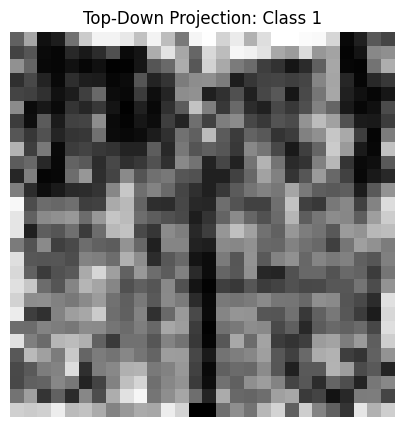

In [76]:
import matplotlib.pyplot as plt

image = x_hat.reshape(28, 28).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title(f"Top-Down Projection: Class {target_class}")
plt.axis("off")
plt.show()

#Tahap 3

In [77]:
#Ekstrak lantent fitur
model.eval()
images,labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
  outputs,zMLP = model(images)

print("Original Images:", images.shape)
print("Latent Features:", zMLP.shape)

Original Images: torch.Size([64, 1, 28, 28])
Latent Features: torch.Size([64, 64])


In [79]:
#Proyeksi balik menggunakan Transpose
with torch.no_grad():

    z = zMLP.cpu()

    h1_hat = F.relu(z @ W2)

    x_hat = torch.sigmoid(h1_hat @ W1)

print("Reconstructed Shape:", x_hat.shape)

Reconstructed Shape: torch.Size([64, 784])


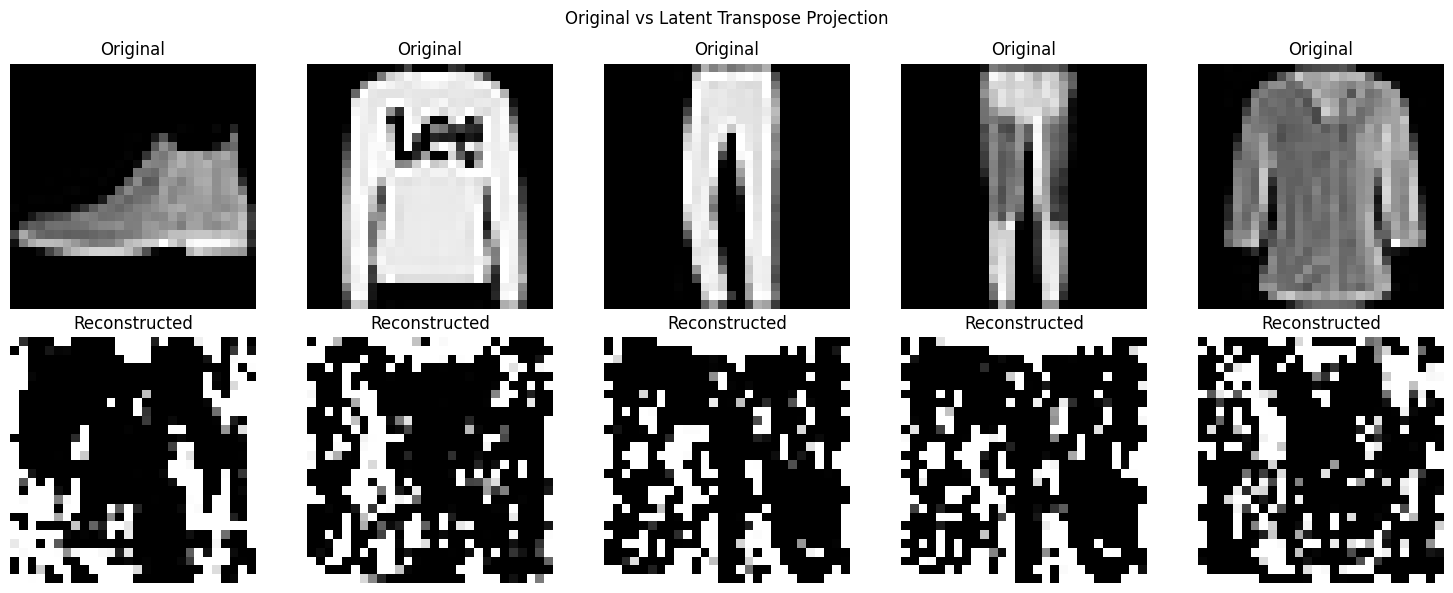

In [81]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):

    original = images[i].cpu().squeeze().numpy()

    reconstructed = x_hat[i].reshape(28, 28).numpy()

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Original vs Latent Transpose Projection")
plt.tight_layout()
plt.show()

In [83]:
#Perbedaan MSE
original = images.cpu().view(-1, 784)

mse = torch.mean((original - x_hat) ** 2)

print("Reconstruction MSE:", mse.item())

Reconstruction MSE: 0.3127988874912262
